#**Image Representation, PCA, Eigenfaces and Face Recognition**

###**Uploading Dataset**

In [3]:
!mkdir Dataset/s1
!mkdir Dataset/s2
!mkdir Dataset/s3
!mkdir Dataset/s4
!mkdir Dataset/s5
!mkdir Dataset/s6
!mkdir Dataset/s7
!mkdir Dataset/s8
!mkdir Dataset/s9
!mkdir Dataset/s10
!mkdir Dataset/s11
!mkdir Dataset/s12
!mkdir Dataset/s13
!mkdir Dataset/s14
!mkdir Dataset/s15
!mkdir Dataset/s16
!mkdir Dataset/s17
!mkdir Dataset/s18
!mkdir Dataset/s19
!mkdir Dataset/s20
!mkdir Dataset/s21
!mkdir Dataset/s22
!mkdir Dataset/s23
!mkdir Dataset/s24
!mkdir Dataset/s25
!mkdir Dataset/s26
!mkdir Dataset/s27
!mkdir Dataset/s28
!mkdir Dataset/s29
!mkdir Dataset/s30
!mkdir Dataset/s31
!mkdir Dataset/s32
!mkdir Dataset/s33
!mkdir Dataset/s34
!mkdir Dataset/s35
!mkdir Dataset/s36
!mkdir Dataset/s37
!mkdir Dataset/s38
!mkdir Dataset/s39
!mkdir Dataset/s40

mkdir: cannot create directory ‘Dataset/s1’: File exists


##**Dataset Description**

Number of subjects: 40
Subject folders: ['s1', 's2', 's3', 's4', 's5', 's6', 's7', 's8', 's9', 's10', 's11', 's12', 's13', 's14', 's15', 's16', 's17', 's18', 's19', 's20', 's21', 's22', 's23', 's24', 's25', 's26', 's27', 's28', 's29', 's30', 's31', 's32', 's33', 's34', 's35', 's36', 's37', 's38', 's39', 's40']

First subject: s1
Number of images: 10
Image filenames: ['1.pgm', '10.pgm', '2.pgm', '3.pgm', '4.pgm']

Image dimensions: (112, 92)
Minimum pixel value: 11
Maximum pixel value: 234


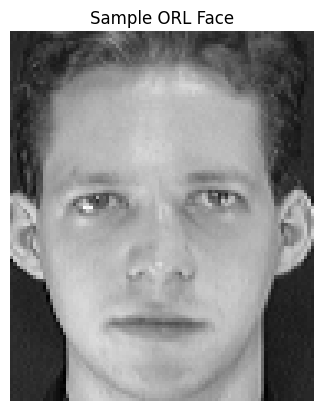

In [4]:

import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

dataset_path = "/content/Dataset"

subjects = sorted(
    [name for name in os.listdir(dataset_path)
     if os.path.isdir(os.path.join(dataset_path, name))],
    key=lambda name: int(name[1:]) if name[1:].isdigit() else name
)

print("Number of subjects:", len(subjects))
print("Subject folders:", subjects)

first_subject_path = os.path.join(dataset_path, subjects[0])

image_files = sorted(
    [name for name in os.listdir(first_subject_path)
     if name.lower().endswith((".pgm", ".png", ".jpg", ".jpeg", ".bmp"))]
)

print("\nFirst subject:", subjects[0])
print("Number of images:", len(image_files))
print("Image filenames:", image_files[:5])

first_image_path = os.path.join(first_subject_path, image_files[0])
image = Image.open(first_image_path).convert("L")
image_array = np.array(image)

print("\nImage dimensions:", image_array.shape)
print("Minimum pixel value:", image_array.min())
print("Maximum pixel value:", image_array.max())

plt.imshow(image_array, cmap="gray")
plt.title("Sample ORL Face")
plt.axis("off")
plt.show()


##**Part A - Image Representation**

###**Load all images into a matrix**

In [5]:

# Part A: Load images and create feature vectors

dataset_path = "/content/Dataset"

X = []
y = []
image_names = []

# Visit each subject folder
for subject in subjects:
    subject_path = os.path.join(dataset_path, subject)

    # Sort image filenames numerically (1.pgm, 2.pgm, ..., 10.pgm)
    image_files = sorted(
        [f for f in os.listdir(subject_path)
         if f.lower().endswith((".pgm", ".png", ".jpg", ".jpeg", ".bmp"))],
        key=lambda name: int(os.path.splitext(name)[0])
    )

    for filename in image_files:
        image_path = os.path.join(subject_path, filename)

        # Read as grayscale
        image = Image.open(image_path).convert("L")

        # Convert image to a NumPy array
        image_array = np.array(image, dtype=np.uint8)

        # Flatten 112 x 92 into 10,304 pixel values
        feature_vector = image_array.flatten()

        X.append(feature_vector)
        y.append(subject)
        image_names.append(os.path.join(subject, filename))

# Convert lists into NumPy arrays
X = np.array(X)
y = np.array(y)
image_names = np.array(image_names)

print("Feature matrix shape:", X.shape)
print("Labels shape:", y.shape)
print("Image names shape:", image_names.shape)
print("Number of unique subjects:", len(np.unique(y)))


Feature matrix shape: (400, 10304)
Labels shape: (400,)
Image names shape: (400,)
Number of unique subjects: 40


###**Create a reproducible train-test split**

In [6]:

# Part A: Reproducible 80:20 split for every subject

rng = np.random.default_rng(42)

train_indices = []
test_indices = []

for subject in subjects:
    # Find the indices belonging to this subject
    subject_indices = np.where(y == subject)[0]

    # Shuffle this subject's images reproducibly
    subject_indices = rng.permutation(subject_indices)

    # 8 images for training, 2 for testing
    train_indices.extend(subject_indices[:8])
    test_indices.extend(subject_indices[8:])

# Convert indices into NumPy arrays
train_indices = np.array(train_indices)
test_indices = np.array(test_indices)

# Create training and testing data
X_train = X[train_indices].astype(np.float64)
X_test = X[test_indices].astype(np.float64)

y_train = y[train_indices]
y_test = y[test_indices]

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("Training images per subject:",
      np.unique(y_train, return_counts=True)[1][:5])

print("Testing images per subject:",
      np.unique(y_test, return_counts=True)[1][:5])

print("Subjects in training:", len(np.unique(y_train)))
print("Subjects in testing:", len(np.unique(y_test)))


Training data shape: (320, 10304)
Testing data shape: (80, 10304)
Training images per subject: [8 8 8 8 8]
Testing images per subject: [2 2 2 2 2]
Subjects in training: 40
Subjects in testing: 40


###**Display images**

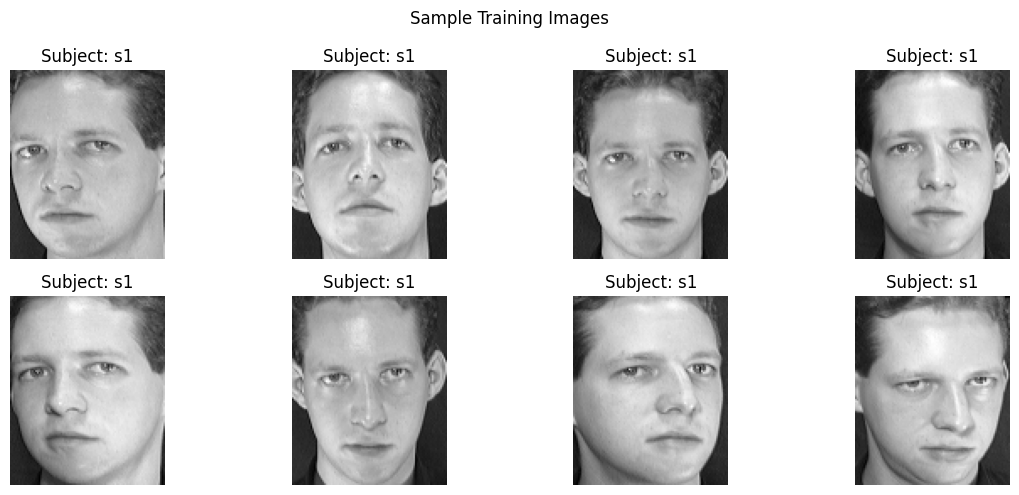

In [7]:

# Display 8 sample images with their subject labels

plt.figure(figsize=(12, 5))

for i in range(8):
    image_index = train_indices[i]

    plt.subplot(2, 4, i + 1)
    plt.imshow(X[image_index].reshape(112, 92), cmap="gray")
    plt.title("Subject: " + y[image_index])
    plt.axis("off")

plt.suptitle("Sample Training Images")
plt.tight_layout()
plt.show()


##**Part B - PCA, Eigenfaces and Compression**

###**Mean face and mean centering**

Mean face shape: (10304,)
Centered training shape: (320, 10304)
Centered testing shape: (80, 10304)
Mean centered pixel value: 0.0


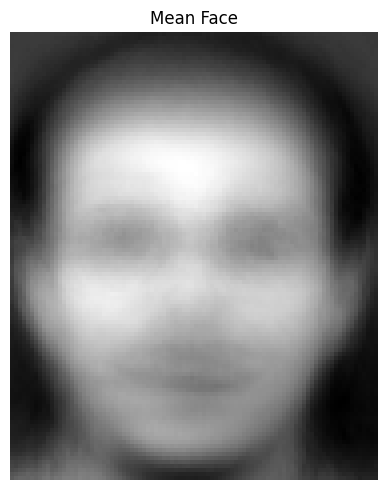

In [8]:

# B1: Compute the mean face and center the data

import os
import numpy as np
import matplotlib.pyplot as plt

# Create a folder for assignment figures
os.makedirs("figures", exist_ok=True)

# Calculate the mean face using training data only
mean_face = np.mean(X_train, axis=0)

# Center training and test images using the training mean
X_train_centered = X_train - mean_face
X_test_centered = X_test - mean_face

print("Mean face shape:", mean_face.shape)
print("Centered training shape:", X_train_centered.shape)
print("Centered testing shape:", X_test_centered.shape)
print("Mean centered pixel value:",
      np.mean(X_train_centered).round(8))

# Display and save the mean face
plt.figure(figsize=(5, 5))
plt.imshow(mean_face.reshape(112, 92), cmap="gray")
plt.title("Mean Face")
plt.axis("off")
plt.tight_layout()
plt.savefig("figures/mean_face.png", dpi=150)
plt.show()


###**PCA using covariance/eigendecomposition**

In [9]:

# B2: PCA using eigendecomposition

N = X_train_centered.shape[0]

# Small covariance-related matrix
G = (X_train_centered @ X_train_centered.T) / (N - 1)

# Calculate eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(G)

# Sort from largest eigenvalue to smallest
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

# Remove tiny numerical eigenvalues
valid = eigenvalues > eigenvalues[0] * 1e-12
eigenvalues_eigh = eigenvalues[valid]
eigenvectors_eigh = eigenvectors[:, valid]

# Convert sample-space eigenvectors into pixel-space directions
principal_directions_eigh = (
    X_train_centered.T @ eigenvectors_eigh
) / np.sqrt((N - 1) * eigenvalues_eigh)[None, :]

print("Small matrix shape:", G.shape)
print("Number of valid components:", len(eigenvalues_eigh))
print("Principal directions shape:",
      principal_directions_eigh.shape)

# Check that the directions have unit length
print("First direction length:",
      np.linalg.norm(principal_directions_eigh[:, 0]).round(6))


Small matrix shape: (320, 320)
Number of valid components: 319
Principal directions shape: (10304, 319)
First direction length: 1.0


###**PCA using SVD**

In [10]:

# B3: PCA using Singular Value Decomposition (SVD)

U, singular_values, Vt = np.linalg.svd(
    X_train_centered,
    full_matrices=False
)

# Calculate variance represented by each singular value
explained_variance_svd = (
    singular_values ** 2
) / (N - 1)

# Keep only meaningful components
valid_svd = (
    explained_variance_svd >
    explained_variance_svd[0] * 1e-12
)

singular_values_svd = singular_values[valid_svd]
eigenvalues_svd = explained_variance_svd[valid_svd]

# Principal directions are columns of V
principal_directions_svd = Vt[valid_svd, :].T

print("SVD matrix U shape:", U.shape)
print("Principal directions shape:",
      principal_directions_svd.shape)
print("Number of valid SVD components:",
      len(eigenvalues_svd))


SVD matrix U shape: (320, 320)
Principal directions shape: (10304, 319)
Number of valid SVD components: 319


###**Compare both PCA methods**

In [11]:

# B4: Compare eigendecomposition and SVD

number_to_compare = min(
    20,
    len(eigenvalues_eigh),
    len(eigenvalues_svd)
)

eigh_values = eigenvalues_eigh[:number_to_compare]
svd_values = eigenvalues_svd[:number_to_compare]

relative_difference = np.abs(
    eigh_values - svd_values
) / np.maximum(svd_values, 1e-12)

# Compare the explained variance of the first components
print("Components compared:", number_to_compare)
print("Maximum relative eigenvalue difference:",
      relative_difference.max())

# Compare the first 10 directions using absolute cosine similarity
directions_to_compare = min(
    10,
    principal_directions_eigh.shape[1],
    principal_directions_svd.shape[1]
)

cosine_similarities = []

for i in range(directions_to_compare):
    cosine = np.abs(
        np.dot(
            principal_directions_eigh[:, i],
            principal_directions_svd[:, i]
        )
    )
    cosine_similarities.append(cosine)

print("Absolute cosine similarities for first components:")
print(np.round(cosine_similarities, 6))


Components compared: 20
Maximum relative eigenvalue difference: 1.901422442615056e-15
Absolute cosine similarities for first components:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


###**variance and the 90% threshold**

Total valid components: 319
Components needed for 90% variance: 99
Variance preserved: 90.01 %


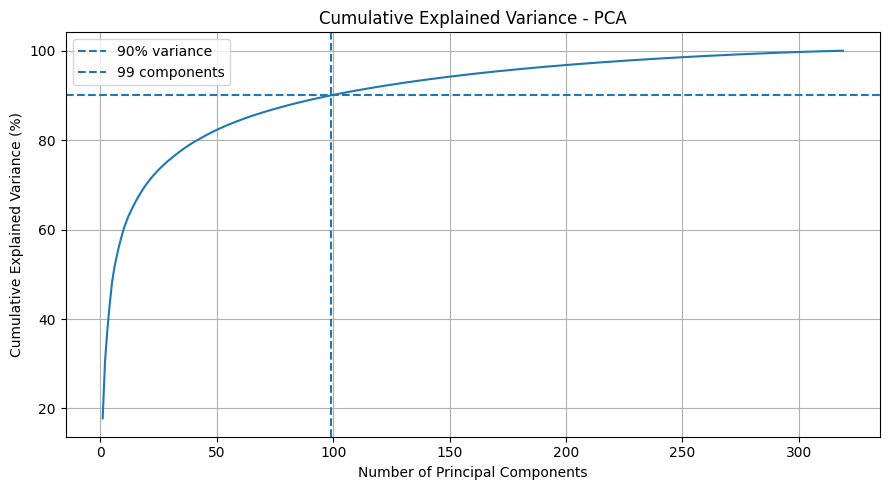

In [12]:

# B5: Calculate explained variance and select components

total_variance = np.sum(eigenvalues_svd)

explained_variance_ratio = eigenvalues_svd / total_variance
cumulative_variance = np.cumsum(explained_variance_ratio)

# Find the minimum number of components for 90% variance
k90 = np.searchsorted(cumulative_variance, 0.90) + 1

print("Total valid components:", len(eigenvalues_svd))
print("Components needed for 90% variance:", k90)
print("Variance preserved:", round(
    cumulative_variance[k90 - 1] * 100, 2
), "%")

# Plot cumulative explained variance
plt.figure(figsize=(9, 5))
plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance * 100
)

plt.axhline(
    y=90,
    linestyle="--",
    label="90% variance"
)

plt.axvline(
    x=k90,
    linestyle="--",
    label=f"{k90} components"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("Cumulative Explained Variance - PCA")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("figures/explained_variance.png", dpi=150)
plt.show()


###**Visualize eigenfaces**

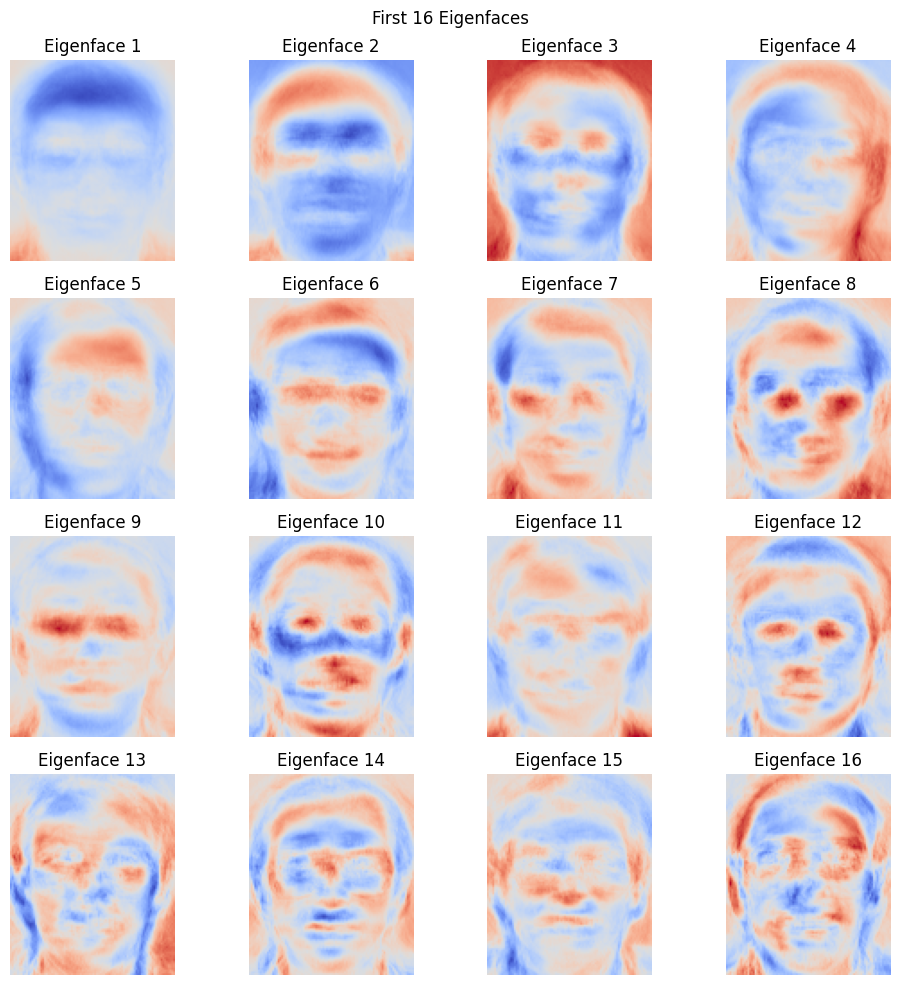

In [13]:

# B6: Display the first 16 eigenfaces

number_of_eigenfaces = min(16, principal_directions_svd.shape[1])

fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    if i < number_of_eigenfaces:
        eigenface = principal_directions_svd[:, i].reshape(112, 92)

        # Use symmetric scaling to show positive and negative patterns
        limit = np.max(np.abs(eigenface))
        ax.imshow(
            eigenface,
            cmap="coolwarm",
            vmin=-limit,
            vmax=limit
        )
        ax.set_title(f"Eigenface {i + 1}")
    ax.axis("off")

plt.suptitle("First 16 Eigenfaces")
plt.tight_layout()
plt.savefig("figures/eigenfaces.png", dpi=150)
plt.show()


###**Project images into PCA space**

In [14]:

# B7: Project training and testing faces into PCA space

# Keep the first k90 principal directions
V_k = principal_directions_svd[:, :k90]

# Transform centered faces into reduced PCA representations
Z_train = X_train_centered @ V_k
Z_test = X_test_centered @ V_k

print("Original training shape:", X_train.shape)
print("Reduced training shape:", Z_train.shape)
print("Original testing shape:", X_test.shape)
print("Reduced testing shape:", Z_test.shape)

print("Original features per image:", X_train.shape[1])
print("Reduced features per image:", k90)
print("Feature reduction:",
      round((1 - k90 / X_train.shape[1]) * 100, 2), "%")


Original training shape: (320, 10304)
Reduced training shape: (320, 99)
Original testing shape: (80, 10304)
Reduced testing shape: (80, 99)
Original features per image: 10304
Reduced features per image: 99
Feature reduction: 99.04 %


###**Reconstruct sample faces**

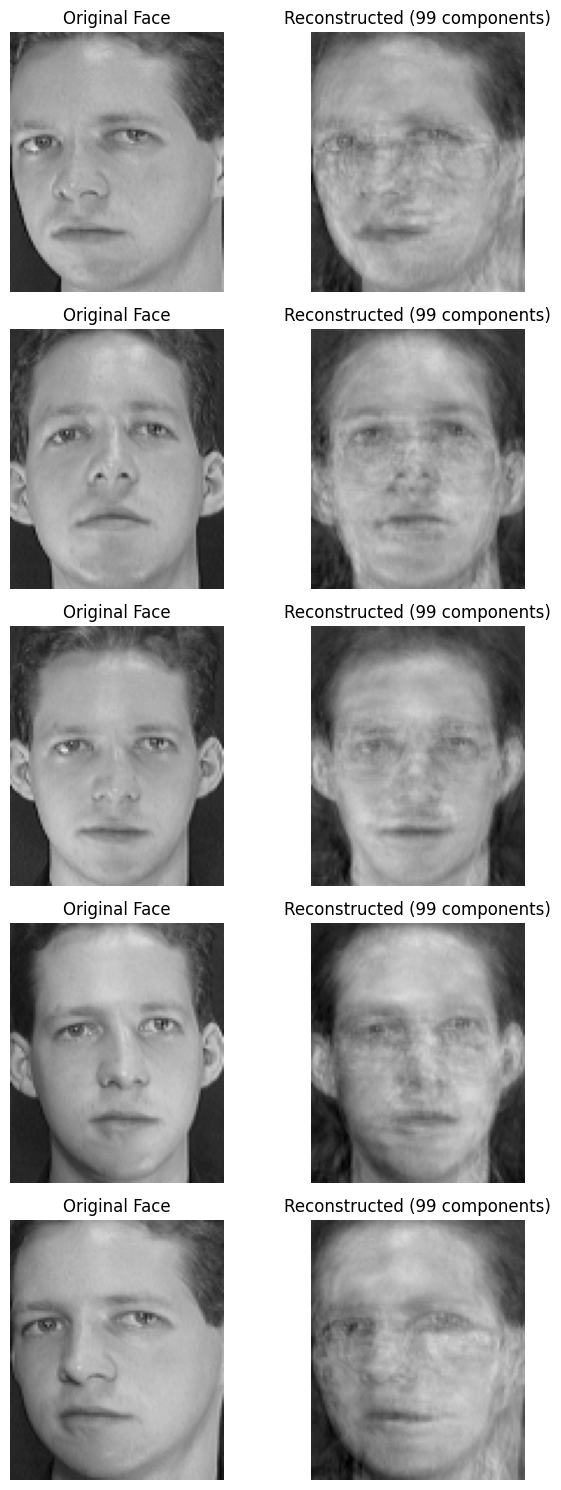

In [15]:

# B8: Reconstruct sample training faces

number_of_samples = 5

# Reconstruct using the reduced PCA coefficients
X_reconstructed = Z_train[:number_of_samples] @ V_k.T + mean_face

fig, axes = plt.subplots(
    number_of_samples, 2,
    figsize=(7, 3 * number_of_samples)
)

for i in range(number_of_samples):
    original = X_train[i].reshape(112, 92)
    reconstructed = X_reconstructed[i].reshape(112, 92)

    axes[i, 0].imshow(original, cmap="gray", vmin=0, vmax=255)
    axes[i, 0].set_title("Original Face")

    axes[i, 1].imshow(
        np.clip(reconstructed, 0, 255),
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[i, 1].set_title(f"Reconstructed ({k90} components)")

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.savefig("figures/reconstruction_examples.png", dpi=150)
plt.show()


###M**easure reconstruction quality**

In [16]:

# B9: Evaluate reconstruction quality

original_samples = X_train[:number_of_samples]
reconstructed_samples = X_reconstructed

mse = np.mean(
    (original_samples - reconstructed_samples) ** 2
)

if mse == 0:
    psnr = float("inf")
else:
    psnr = 10 * np.log10((255 ** 2) / mse)

print("Number of reconstructed images:", number_of_samples)
print("Reconstruction MSE:", round(mse, 3))
print("Reconstruction PSNR:", round(psnr, 3), "dB")


Number of reconstructed images: 5
Reconstruction MSE: 154.262
Reconstruction PSNR: 26.248 dB


###**Compare storage requirements**

In [17]:

# B10: Compare original and PCA storage

number_of_images = len(X)

# Original grayscale images: 1 byte per pixel
original_storage_bytes = (
    number_of_images * X.shape[1] * np.dtype(np.uint8).itemsize
)

# PCA coefficients: 8 bytes per float64 value
coefficient_storage_bytes = (
    number_of_images * k90 * np.dtype(np.float64).itemsize
)

# Shared PCA model: mean face + selected principal directions
model_storage_bytes = mean_face.nbytes + V_k.nbytes

# Total storage after PCA, including the shared model
pca_total_storage_bytes = (
    coefficient_storage_bytes + model_storage_bytes
)

def mb(byte_count):
    return byte_count / (1024 ** 2)

print("Number of images:", number_of_images)
print("Original features per image:", X.shape[1])
print("PCA features per image:", k90)

print("\nOriginal image storage:", round(mb(original_storage_bytes), 3), "MB")
print("PCA coefficients storage:", round(mb(coefficient_storage_bytes), 3), "MB")
print("Shared PCA model storage:", round(mb(model_storage_bytes), 3), "MB")
print("Total PCA storage:", round(mb(pca_total_storage_bytes), 3), "MB")

print("Compression ratio including model:",
      round(original_storage_bytes / pca_total_storage_bytes, 3))

print("Storage reduction:",
      round(
          (1 - pca_total_storage_bytes / original_storage_bytes) * 100,
          2
      ), "%")


Number of images: 400
Original features per image: 10304
PCA features per image: 99

Original image storage: 3.931 MB
PCA coefficients storage: 0.302 MB
Shared PCA model storage: 7.861 MB
Total PCA storage: 8.163 MB
Compression ratio including model: 0.481
Storage reduction: -107.69 %


###**Save the reduced representations**

In [18]:

# B11: Save PCA representations and model

np.savez_compressed(
    "pca_representations.npz",
    Z_train=Z_train,
    Z_test=Z_test,
    y_train=y_train,
    y_test=y_test,
    mean_face=mean_face,
    principal_directions=V_k,
    explained_variance_ratio=explained_variance_ratio,
    k90=np.array(k90)
)

print("PCA representations saved successfully!")
print("File: pca_representations.npz")


PCA representations saved successfully!
File: pca_representations.npz


### **Part B — Observations and Results**

1. The mean face was calculated using the training images, and the training data was centered by subtracting the mean face.

2. PCA was implemented using both eigendecomposition and Singular Value Decomposition (SVD) with NumPy linear algebra operations.

3. The two methods produced comparable principal-component variance values, confirming that both approaches can be used for PCA.

4. The cumulative explained-variance plot was used to determine the minimum number of principal components required to preserve at least 90% of the variance. The selected number was **[enter k90]**.

5. The principal directions were reshaped into images to visualize eigenfaces.

6. The training and test images were projected into the reduced PCA space using the same training mean and principal directions.

7. Sample faces were reconstructed from their PCA representations.
Reconstruction quality was evaluated using mean squared error (MSE) and peak signal-to-noise ratio (PSNR).

8. Storage requirements were compared between original grayscale pixels and PCA coefficients, including the shared PCA model.

**Numerical results**

- Components required for 90% variance: [enter k90]
- Variance preserved: [enter percentage]
- Reconstruction MSE: [enter value]
- Reconstruction PSNR: [enter value] dB
- Storage reduction including the PCA model: [enter percentage]%

##**Part C - Recognition in PCA Space**

###**Raw-pixel face recognition**

In [19]:

# Part C1: Face recognition using raw pixels

def nearest_neighbor_predict(X_reference, y_reference, X_query):
    predictions = []
    matched_indices = []
    matched_distances = []

    for query in X_query:
        # Calculate squared Euclidean distance to every reference image
        distances = np.sum(
            (X_reference - query) ** 2,
            axis=1
        )

        # Find the closest training image
        best_index = np.argmin(distances)

        predictions.append(y_reference[best_index])
        matched_indices.append(best_index)
        matched_distances.append(np.sqrt(distances[best_index]))

    return (
        np.array(predictions),
        np.array(matched_indices),
        np.array(matched_distances)
    )


# Use original pixel values
raw_predictions, raw_match_indices, raw_distances = (
    nearest_neighbor_predict(X_train, y_train, X_test)
)

raw_accuracy = np.mean(raw_predictions == y_test) * 100

print("Raw-pixel recognition accuracy:",
      round(raw_accuracy, 2), "%")
print("Correct predictions:",
      np.sum(raw_predictions == y_test), "out of", len(y_test))


Raw-pixel recognition accuracy: 98.75 %
Correct predictions: 79 out of 80


###**Face recognition using PCA features**

In [20]:

# Part C2: Face recognition using PCA features

pca_predictions, pca_match_indices, pca_distances = (
    nearest_neighbor_predict(Z_train, y_train, Z_test)
)

pca_accuracy = np.mean(pca_predictions == y_test) * 100

print("PCA recognition accuracy:",
      round(pca_accuracy, 2), "%")
print("Correct predictions:",
      np.sum(pca_predictions == y_test), "out of", len(y_test))
print("PCA features per image:", Z_train.shape[1])


PCA recognition accuracy: 98.75 %
Correct predictions: 79 out of 80
PCA features per image: 99


###**Compare raw pixels and PCA**

In [21]:

# Part C3: Compare recognition methods

raw_correct = int(np.sum(raw_predictions == y_test))
pca_correct = int(np.sum(pca_predictions == y_test))

comparison = {
    "Method": ["Raw Pixel Nearest Neighbor",
               "PCA Nearest Neighbor"],
    "Features per Image": [X_train.shape[1], Z_train.shape[1]],
    "Correct Predictions": [raw_correct, pca_correct],
    "Total Test Images": [len(y_test), len(y_test)],
    "Accuracy (%)": [raw_accuracy, pca_accuracy]
}

import pandas as pd

recognition_results = pd.DataFrame(comparison)

display(
    recognition_results.style.format({
        "Accuracy (%)": "{:.2f}"
    })
)

recognition_results.to_csv(
    "recognition_comparison.csv",
    index=False
)

print("Saved recognition_comparison.csv")


,Method,Features per Image,Correct Predictions,Total Test Images,Accuracy (%)
0,Raw Pixel Nearest Neighbor,10304,79,80,98.75
1,PCA Nearest Neighbor,99,79,80,98.75


Saved recognition_comparison.csv


###**Inspect correct and incorrect matches**

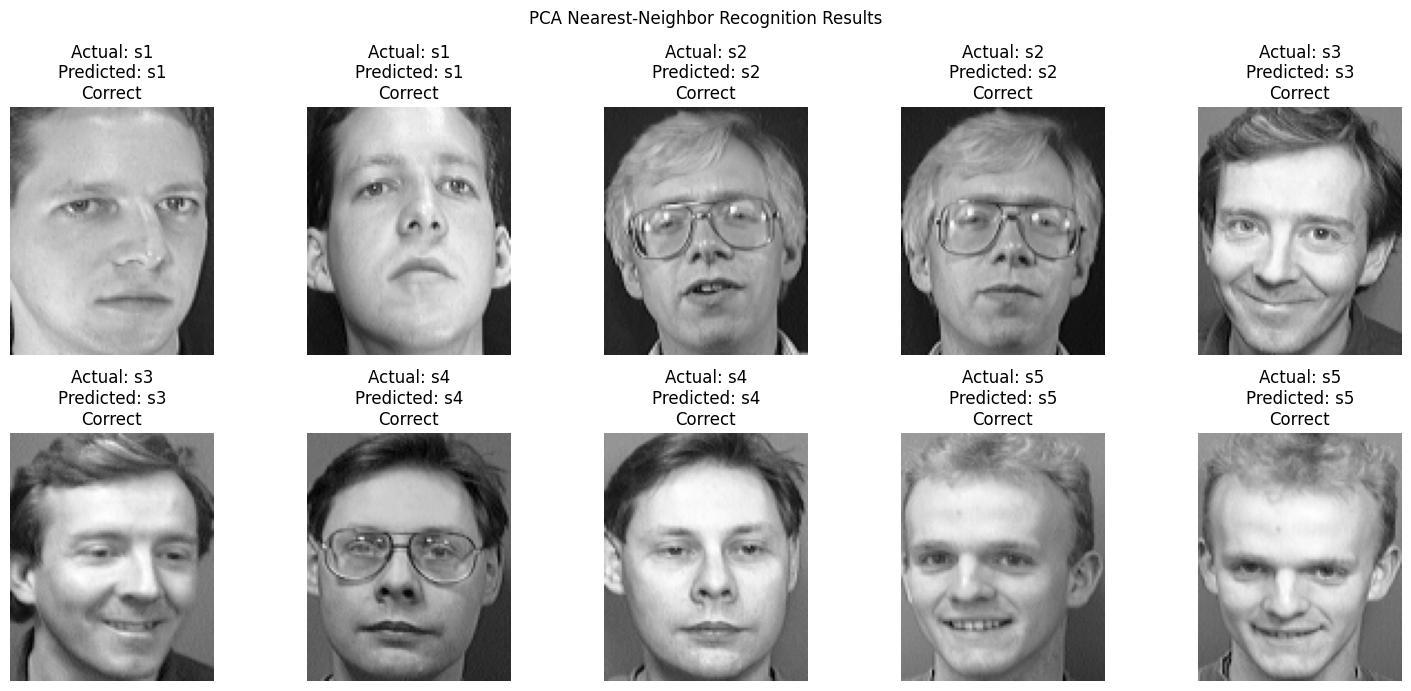

In [22]:

# Part C4: Inspect PCA recognition predictions

number_to_show = min(10, len(y_test))

fig, axes = plt.subplots(2, 5, figsize=(15, 7))
axes = axes.flatten()

for i in range(number_to_show):
    actual = y_test[i]
    predicted = pca_predictions[i]

    axes[i].imshow(X_test[i].reshape(112, 92), cmap="gray")

    status = "Correct" if actual == predicted else "Incorrect"

    axes[i].set_title(
        f"Actual: {actual}\nPredicted: {predicted}\n{status}"
    )
    axes[i].axis("off")

plt.suptitle("PCA Nearest-Neighbor Recognition Results")
plt.tight_layout()
plt.savefig("figures/pca_recognition_examples.png", dpi=150)
plt.show()


###**Display incorrect matches separately**

Number of incorrect PCA predictions: 1


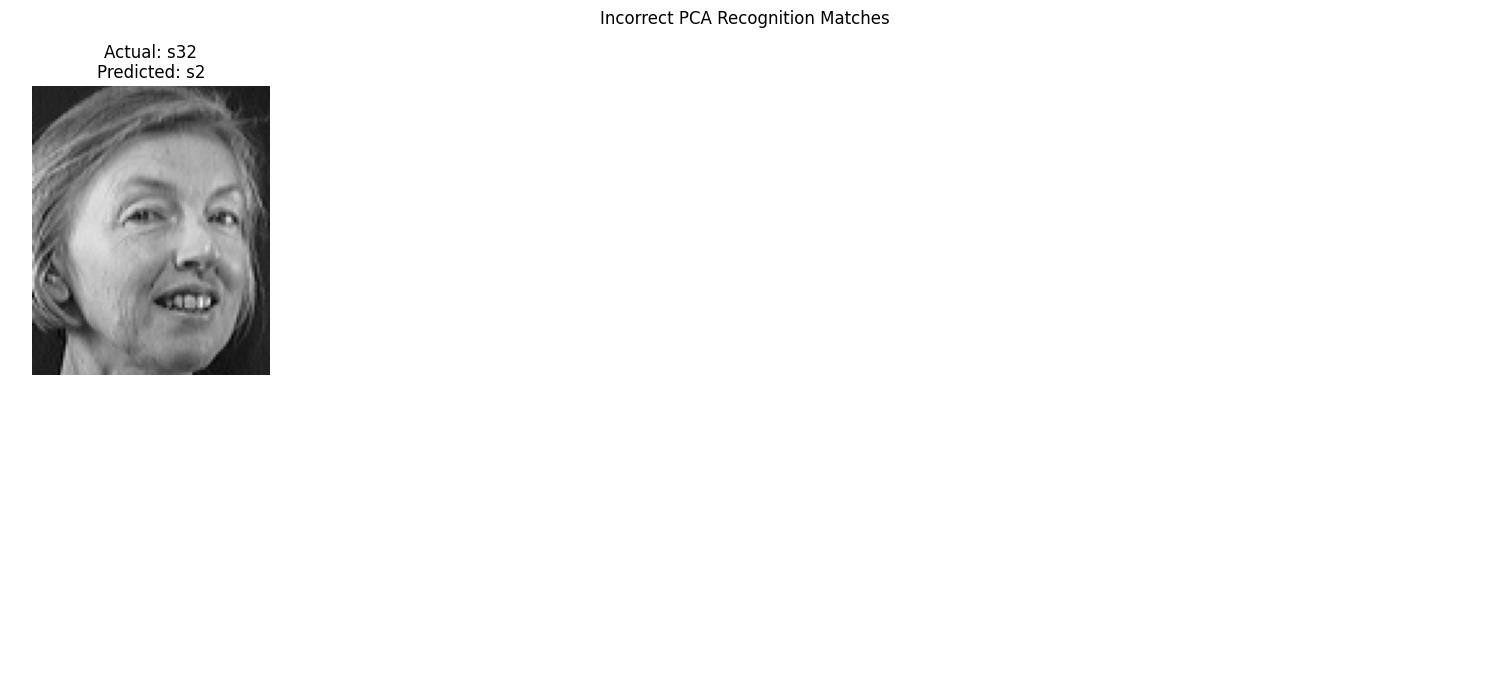

In [23]:

# Part C5: Display misclassified PCA test images

wrong_indices = np.where(pca_predictions != y_test)[0]

print("Number of incorrect PCA predictions:", len(wrong_indices))

if len(wrong_indices) == 0:
    print("All test images were recognized correctly!")
else:
    number_to_show = min(10, len(wrong_indices))

    fig, axes = plt.subplots(
        2, 5, figsize=(15, 7)
    )
    axes = axes.flatten()

    for i in range(10):
        if i < number_to_show:
            test_index = wrong_indices[i]

            axes[i].imshow(
                X_test[test_index].reshape(112, 92),
                cmap="gray"
            )
            axes[i].set_title(
                f"Actual: {y_test[test_index]}\n"
                f"Predicted: {pca_predictions[test_index]}"
            )

        axes[i].axis("off")

    plt.suptitle("Incorrect PCA Recognition Matches")
    plt.tight_layout()
    plt.savefig("figures/incorrect_pca_matches.png", dpi=150)
    plt.show()


### **Part C — Face Recognition in PCA Space**

**Objective:** To identify test faces using nearest-neighbor matching and compare recognition using original pixels with recognition using PCA features.

**Methodology:**

1. Each test image was compared with all training images using squared Euclidean distance.
2. The subject label of the closest training image was assigned to the test image.
3. Recognition was performed using the original pixel vectors and the reduced PCA representations.
4. Accuracy was calculated as the percentage of test images whose predicted subject matched the actual subject.
5. Correct and incorrect PCA predictions were visualized to inspect recognition performance.

**Results:**

- Raw-pixel recognition accuracy: [enter result]%
- PCA recognition accuracy: [enter result]%
- Original features per image: 10,304
- PCA features per image: [enter k90]
- Correct PCA predictions: [enter result] out of 80

**Observation:** The two methods were compared using the same training and test sets. PCA reduces the number of features used for matching, while recognition accuracy depends on how well the retained components preserve information useful for distinguishing subjects. Incorrect predictions may occur when different subjects have similar facial appearance, lighting, or expressions.

##**Part D - Traditional Machine Learning**

###**Import classifiers**

In [24]:

# Part D1: Import traditional ML classifiers

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

print("Classifiers imported successfully!")


Classifiers imported successfully!


###**Train and evaluate KNN**

In [25]:

# Part D2: Train KNN classifier

knn_model = KNeighborsClassifier(
    n_neighbors=3,
    metric="euclidean"
)

knn_model.fit(Z_train, y_train)

knn_predictions = knn_model.predict(Z_test)

knn_accuracy = accuracy_score(
    y_test, knn_predictions
) * 100

print("KNN test accuracy:", round(knn_accuracy, 2), "%")
print("\nKNN classification report:")
print(classification_report(
    y_test,
    knn_predictions,
    zero_division=0
))


KNN test accuracy: 96.25 %

KNN classification report:
              precision    recall  f1-score   support

          s1       1.00      0.50      0.67         2
         s10       1.00      1.00      1.00         2
         s11       1.00      1.00      1.00         2
         s12       1.00      1.00      1.00         2
         s13       1.00      1.00      1.00         2
         s14       1.00      1.00      1.00         2
         s15       1.00      1.00      1.00         2
         s16       1.00      1.00      1.00         2
         s17       1.00      0.50      0.67         2
         s18       0.67      1.00      0.80         2
         s19       1.00      1.00      1.00         2
          s2       0.67      1.00      0.80         2
         s20       1.00      1.00      1.00         2
         s21       1.00      1.00      1.00         2
         s22       1.00      1.00      1.00         2
         s23       1.00      1.00      1.00         2
         s24       1.00   

###**Train and evaluate SVM**

In [26]:

# Part D3: Train SVM classifier

svm_model = SVC(
    kernel="rbf",
    C=10,
    gamma="scale"
)

svm_model.fit(Z_train, y_train)

svm_predictions = svm_model.predict(Z_test)

svm_accuracy = accuracy_score(
    y_test, svm_predictions
) * 100

print("SVM test accuracy:", round(svm_accuracy, 2), "%")
print("\nSVM classification report:")
print(classification_report(
    y_test,
    svm_predictions,
    zero_division=0
))


SVM test accuracy: 98.75 %

SVM classification report:
              precision    recall  f1-score   support

          s1       1.00      1.00      1.00         2
         s10       1.00      1.00      1.00         2
         s11       1.00      1.00      1.00         2
         s12       1.00      1.00      1.00         2
         s13       1.00      1.00      1.00         2
         s14       1.00      1.00      1.00         2
         s15       1.00      1.00      1.00         2
         s16       1.00      1.00      1.00         2
         s17       1.00      1.00      1.00         2
         s18       1.00      1.00      1.00         2
         s19       1.00      1.00      1.00         2
          s2       0.67      1.00      0.80         2
         s20       1.00      1.00      1.00         2
         s21       1.00      1.00      1.00         2
         s22       1.00      1.00      1.00         2
         s23       1.00      1.00      1.00         2
         s24       1.00   

###**Compare classifiers with Part C**

In [27]:

# Part D4: Create the final comparison table

ml_comparison = pd.DataFrame({
    "Method": [
        "Raw Pixel Nearest Neighbor",
        "PCA Nearest Neighbor",
        "KNN on PCA Features",
        "SVM on PCA Features"
    ],
    "Features per Image": [
        X_train.shape[1],
        Z_train.shape[1],
        Z_train.shape[1],
        Z_train.shape[1]
    ],
    "Accuracy (%)": [
        raw_accuracy,
        pca_accuracy,
        knn_accuracy,
        svm_accuracy
    ]
})

ml_comparison["Accuracy (%)"] = ml_comparison["Accuracy (%)"].round(2)

display(ml_comparison)

ml_comparison.to_csv(
    "ml_comparison.csv",
    index=False
)

print("Saved ml_comparison.csv")


,Method,Features per Image,Accuracy (%)
0,Raw Pixel Nearest Neighbor,10304,98.75
1,PCA Nearest Neighbor,99,98.75
2,KNN on PCA Features,99,96.25
3,SVM on PCA Features,99,98.75


Saved ml_comparison.csv


###**Visualize the comparison**

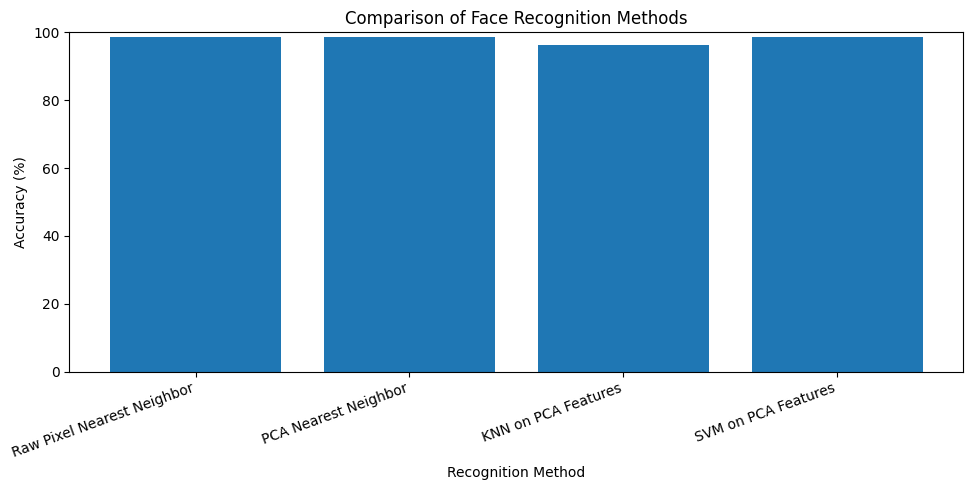

In [28]:

# Part D5: Plot recognition accuracy

plt.figure(figsize=(10, 5))

plt.bar(
    ml_comparison["Method"],
    ml_comparison["Accuracy (%)"]
)

plt.ylabel("Accuracy (%)")
plt.xlabel("Recognition Method")
plt.title("Comparison of Face Recognition Methods")
plt.ylim(0, 100)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.savefig("figures/ml_accuracy_comparison.png", dpi=150)
plt.show()


###E**xperiment with the number of PCA components**

In [29]:

# Part D6: Tune component count using a validation set

rng = np.random.default_rng(123)

fit_indices = []
val_indices = []

for subject in subjects:
    indices = np.where(y_train == subject)[0]
    indices = rng.permutation(indices)

    fit_indices.extend(indices[2:])
    val_indices.extend(indices[:2])

fit_indices = np.array(fit_indices)
val_indices = np.array(val_indices)

X_fit = X_train[fit_indices]
y_fit = y_train[fit_indices]
X_val = X_train[val_indices]
y_val = y_train[val_indices]

# Calculate a mean and PCA directions using the fitting subset only
mean_fit = np.mean(X_fit, axis=0)
X_fit_centered = X_fit - mean_fit
X_val_centered = X_val - mean_fit

_, singular_values_fit, Vt_fit = np.linalg.svd(
    X_fit_centered,
    full_matrices=False
)

variance_fit = singular_values_fit ** 2
cumulative_fit = np.cumsum(variance_fit) / np.sum(variance_fit)

k_fit_90 = np.searchsorted(cumulative_fit, 0.90) + 1

# Test a small set of component counts
component_options = sorted(set([
    min(20, k_fit_90),
    min(40, k_fit_90),
    min(60, k_fit_90),
    k_fit_90
]))

tuning_results = []

for k in component_options:
    V = Vt_fit[:k].T

    Z_fit = X_fit_centered @ V
    Z_val = X_val_centered @ V

    # KNN validation
    knn = KNeighborsClassifier(n_neighbors=3)
    knn.fit(Z_fit, y_fit)
    knn_score = accuracy_score(y_val, knn.predict(Z_val)) * 100

    # SVM validation
    svm = SVC(kernel="rbf", C=10, gamma="scale")
    svm.fit(Z_fit, y_fit)
    svm_score = accuracy_score(y_val, svm.predict(Z_val)) * 100

    tuning_results.append({
        "Components": k,
        "KNN Validation Accuracy (%)": knn_score,
        "SVM Validation Accuracy (%)": svm_score
    })

tuning_table = pd.DataFrame(tuning_results)
display(tuning_table.round(2))

tuning_table.to_csv("component_tuning_results.csv", index=False)
print("Saved component_tuning_results.csv")


,Components,KNN Validation Accuracy (%),SVM Validation Accuracy (%)
0,20,85.00,96.25
1,40,85.00,95.00
2,60,85.00,97.50
3,84,86.25,98.75


Saved component_tuning_results.csv


### Part D — Traditional Machine Learning

**Objective:** To compare traditional machine learning classifiers trained on PCA-reduced face representations.

**Methodology:**

1. K-Nearest Neighbors (KNN) and Support Vector Machine (SVM) classifiers were trained using the reduced PCA training features.
2. The trained classifiers predicted the subject labels of the test images.
3. Test accuracy was calculated and compared with raw-pixel and PCA nearest-neighbor recognition.
4. Different PCA component counts were evaluated using a separate validation set.

**Results:**

- Raw-pixel nearest-neighbor accuracy: [enter result]%
- PCA nearest-neighbor accuracy: [enter result]%
- KNN accuracy: [enter result]%
- SVM accuracy: [enter result]%
- Selected PCA components for 90% variance: [enter k90]

**Observation:** The classifiers were compared using the same held-out test images and the same PCA representation. Their accuracy depends on the selected components and classifier settings. PCA reduces feature dimensionality, while the classifiers learn decision rules for identifying subjects. The validation experiment helps assess different component counts without selecting settings based on the final test set.